In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

SEED = 20260811
rng = np.random.default_rng(SEED)
plt.style.use("seaborn-v0_8-whitegrid")

Python/data. Use lecture_05_examples.ipynb as a starting point. For each fixed
$λ∈{1,5,10}$ and each $n∈{λ,2λ,5λ,10λ,50λ,100λ}$, let
$$X_n ∼Binomial(n,λ/n), Y∼Poisson(λ).$$
Here $p:= λ/n∈(0,1]$, and the case n= λ is a binomial count with success probability one.
Compare these fixed model laws; no Monte Carlo simulation is needed.
## (a)
Plot $d_{TV}(p_{X_n} ,p_Y)$ against n, using one curve for each λ. Include the full Poisson
probability above n, as in (5.16).

$$
d_{\mathrm{TV}}(p_X,p_Y)\coloneqq\frac12\sum_{k=0}^{\infty}|p_X(k)-p_Y(k)|.\tag{1}
$$
For $n\in\mathbb N$ and $p\in(0,1]$, let $X\sim\operatorname{Binomial}(n,p)$ and $Y\sim\operatorname{Poisson}(np)$. Since $p_X(k)=0$ for every integer $k>n$, equation (1) becomes

$$
d_{\mathrm{TV}}(p_X,p_Y)
=\frac12\left[\sum_{k=0}^{n}|p_X(k)-p_Y(k)|+\mathbb P(Y>n)\right].\tag{2}
$$

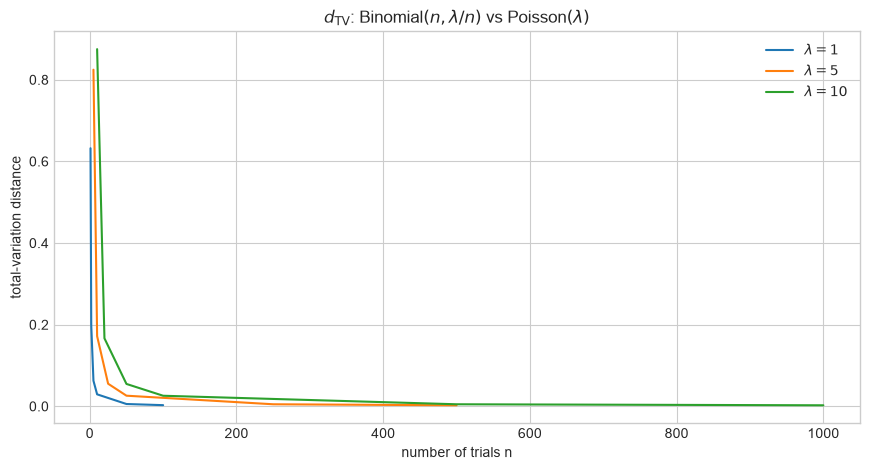

lambda= 1  n=    1  p=1       d_TV=0.632121
lambda= 1  n=    2  p=0.5     d_TV=0.198181
lambda= 1  n=    5  p=0.2     d_TV=0.062581
lambda= 1  n=   10  p=0.1     d_TV=0.029312
lambda= 1  n=   50  p=0.02    d_TV=0.005583
lambda= 1  n=  100  p=0.01    d_TV=0.002775
lambda= 5  n=    5  p=1       d_TV=0.824533
lambda= 5  n=   10  p=0.5     d_TV=0.171835
lambda= 5  n=   25  p=0.2     d_TV=0.055282
lambda= 5  n=   50  p=0.1     d_TV=0.025959
lambda= 5  n=  250  p=0.02    d_TV=0.004953
lambda= 5  n=  500  p=0.01    d_TV=0.002462
lambda=10  n=   10  p=1       d_TV=0.874890
lambda=10  n=   20  p=0.5     d_TV=0.166509
lambda=10  n=   50  p=0.2     d_TV=0.054760
lambda=10  n=  100  p=0.1     d_TV=0.025829
lambda=10  n=  500  p=0.02    d_TV=0.004942
lambda=10  n= 1000  p=0.01    d_TV=0.002458


In [8]:
def total_variation_binomial_poisson(n_trials, probability):
    lambda_ = n_trials * probability
    support = np.arange(0, n_trials + 1)
    point_difference = np.abs(
        stats.binom(n=n_trials, p=probability).pmf(support)
        - stats.poisson(mu=lambda_).pmf(support)
    ).sum()
    poisson_tail = stats.poisson(mu=lambda_).sf(n_trials)
    return 0.5 * (point_difference + poisson_tail)

lambda_values = [1, 5, 10]
multipliers = np.array([1, 2, 5, 10, 50, 100])

tv_by_lambda = {}
fig, ax = plt.subplots(figsize=(8.8, 4.8))
for lambda_ in lambda_values:
    n_values = multipliers * lambda_
    tv_values = np.array([
        total_variation_binomial_poisson(int(n_trials), lambda_ / n_trials)   # p = λ/n, so np = λ
        for n_trials in n_values
    ])
    tv_by_lambda[lambda_] = (n_values, tv_values)
    ax.plot(n_values, tv_values, label=rf"$\lambda={lambda_}$")

ax.set_xlabel("number of trials n")
ax.set_ylabel("total-variation distance")
ax.set_title(r"$d_{\mathrm{TV}}$: Binomial$(n,\lambda/n)$ vs Poisson$(\lambda)$")
ax.legend()
plt.tight_layout()
plt.show()

for lambda_, (n_values, tv_values) in tv_by_lambda.items():
    for n_trials, tv in zip(n_values, tv_values):
        print(f"lambda={lambda_:>2}  n={n_trials:>5}  p={lambda_ / n_trials:<6.4g}  d_TV={tv:.6f}")

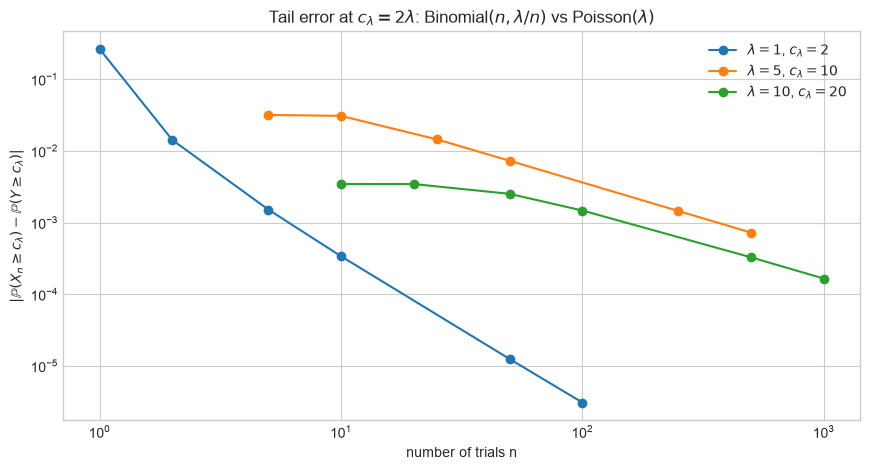

lambda= 1  c= 2  n=    1  p=1       tail error=0.264241
lambda= 1  c= 2  n=    2  p=0.5     tail error=0.014241
lambda= 1  c= 2  n=    5  p=0.2     tail error=0.001521
lambda= 1  c= 2  n=   10  p=0.1     tail error=0.000340
lambda= 1  c= 2  n=   50  p=0.02    tail error=0.000013
lambda= 1  c= 2  n=  100  p=0.01    tail error=0.000003
lambda= 5  c=10  n=    5  p=1       tail error=0.031828
lambda= 5  c=10  n=   10  p=0.5     tail error=0.030851
lambda= 5  c=10  n=   25  p=0.2     tail error=0.014496
lambda= 5  c=10  n=   50  p=0.1     tail error=0.007290
lambda= 5  c=10  n=  250  p=0.02    tail error=0.001453
lambda= 5  c=10  n=  500  p=0.01    tail error=0.000726
lambda=10  c=20  n=   10  p=1       tail error=0.003454
lambda=10  c=20  n=   20  p=0.5     tail error=0.003453
lambda=10  c=20  n=   50  p=0.2     tail error=0.002522
lambda=10  c=20  n=  100  p=0.1     tail error=0.001476
lambda=10  c=20  n=  500  p=0.02    tail error=0.000328
lambda=10  c=20  n= 1000  p=0.01    tail error=0

In [10]:
tail_error_by_lambda = {}
fig, ax = plt.subplots(figsize=(8.8, 4.8))
for lambda_ in lambda_values:
    threshold = 2 * lambda_
    poisson_tail = stats.poisson(mu=lambda_).sf(threshold - 1)          # P(Y >= c), fixed in n
    n_values = multipliers * lambda_
    errors = np.array([
        abs(stats.binom(n=int(n_trials), p=lambda_ / n_trials).sf(threshold - 1) - poisson_tail)
        for n_trials in n_values
    ])
    tail_error_by_lambda[lambda_] = (n_values, errors)
    ax.plot(n_values, errors, marker="o", label=rf"$\lambda={lambda_}$, $c_\lambda={threshold}$")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("number of trials n")
ax.set_ylabel(r"$|\mathbb{P}(X_n\geq c_\lambda)-\mathbb{P}(Y\geq c_\lambda)|$")
ax.set_title(r"Tail error at $c_\lambda=2\lambda$: Binomial$(n,\lambda/n)$ vs Poisson$(\lambda)$")
ax.legend()
plt.tight_layout()
plt.show()

for lambda_, (n_values, errors) in tail_error_by_lambda.items():
    for n_trials, err in zip(n_values, errors):
        print(f"lambda={lambda_:>2}  c={2 * lambda_:>2}  n={n_trials:>5}  "
              f"p={lambda_ / n_trials:<6.4g}  tail error={err:.6f}")

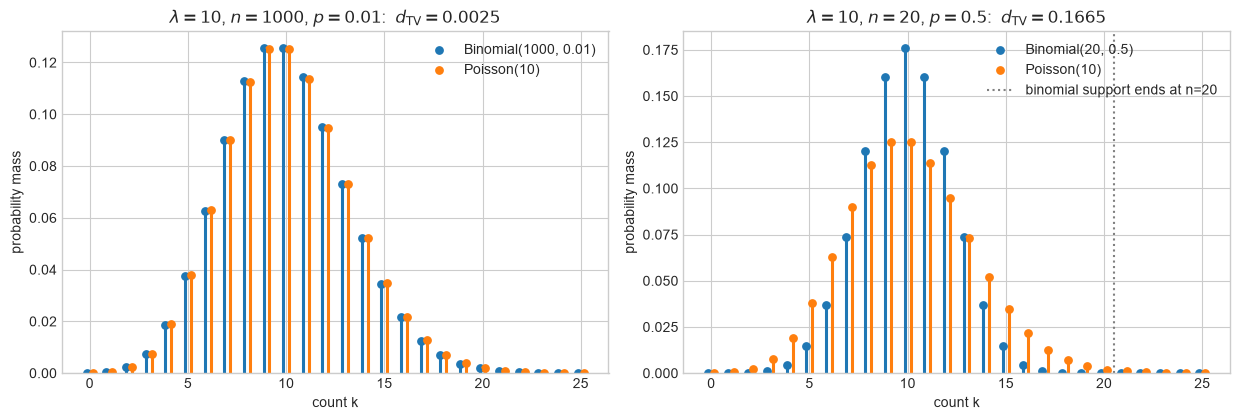

lambda=10, n=1000, p=0.01: d_TV=0.002458, Var(X_n)=9.90 vs Var(Y)=10, P(Y > n)=0.00e+00
lambda=10, n=20, p=0.5: d_TV=0.166509, Var(X_n)=5.00 vs Var(Y)=10, P(Y > n)=1.59e-03


In [12]:
pairs = [(10, 1_000), (10, 20)]     # (λ, n): p = 0.01 vs p = 0.5
support = np.arange(0, 26)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
for ax, (lambda_, n_trials) in zip(axes, pairs):
    p_now = lambda_ / n_trials
    binom_pmf = stats.binom(n=n_trials, p=p_now).pmf(support)
    poisson_pmf = stats.poisson(mu=lambda_).pmf(support)
    tv = total_variation_binomial_poisson(n_trials, p_now)

    ax.vlines(support - 0.15, 0, binom_pmf, color="tab:blue", linewidth=2.2)
    ax.scatter(support - 0.15, binom_pmf, color="tab:blue", s=28, label=f"Binomial({n_trials}, {p_now:g})")
    ax.vlines(support + 0.15, 0, poisson_pmf, color="tab:orange", linewidth=2.2)
    ax.scatter(support + 0.15, poisson_pmf, color="tab:orange", s=28, label=f"Poisson({lambda_})")
    if n_trials < support[-1]:
        ax.axvline(n_trials + 0.5, color="gray", linestyle=":", label=f"binomial support ends at n={n_trials}")
    ax.set_title(rf"$\lambda={lambda_}$, $n={n_trials}$, $p={p_now:g}$:  $d_{{\mathrm{{TV}}}}={tv:.4f}$")
    ax.set_xlabel("count k")
    ax.set_ylabel("probability mass")
    ax.set_ylim(bottom=0)
    ax.legend()
plt.tight_layout()
plt.show()

for lambda_, n_trials in pairs:
    p_now = lambda_ / n_trials
    print(f"lambda={lambda_}, n={n_trials}, p={p_now:g}: "
          f"d_TV={total_variation_binomial_poisson(n_trials, p_now):.6f}, "
          f"Var(X_n)={n_trials * p_now * (1 - p_now):.2f} vs Var(Y)={lambda_}, "
          f"P(Y > n)={stats.poisson(mu=lambda_).sf(n_trials):.2e}")

3. **Python/data:** Use `lecture_06_examples.ipynb` as a starting point. Simulate 30,000 independent waiting times with law $\operatorname{Exp}(2)$. Fix $s=0.5$; retain only waits exceeding $s$, then subtract $s$ to obtain the remaining waits. Plot the empirical survival curves of the original and remaining waits together with $e^{-2t}$ for $t\geq0$. For both samples, tabulate the empirical 0.1, 0.5, and 0.9 quantiles alongside the exponential quantiles, using `method="inverted_cdf"` in `np.quantile`. Report the largest absolute discrepancy from the theoretical survival curve on a stated finite grid. Repeat the survival-curve comparison for 30,000 independent waits with law $\operatorname{Unif}(0,1)$, keeping $s=0.5$, and derive $\mathbb P(T>s+t\mid T>s)$ for every $t\geq0$ under that model. Explain why the two models behave differently and identify SciPy's reciprocal-rate argument.

retained waits: 11003 of 30000 (theory: P(T > s) = 0.3679)


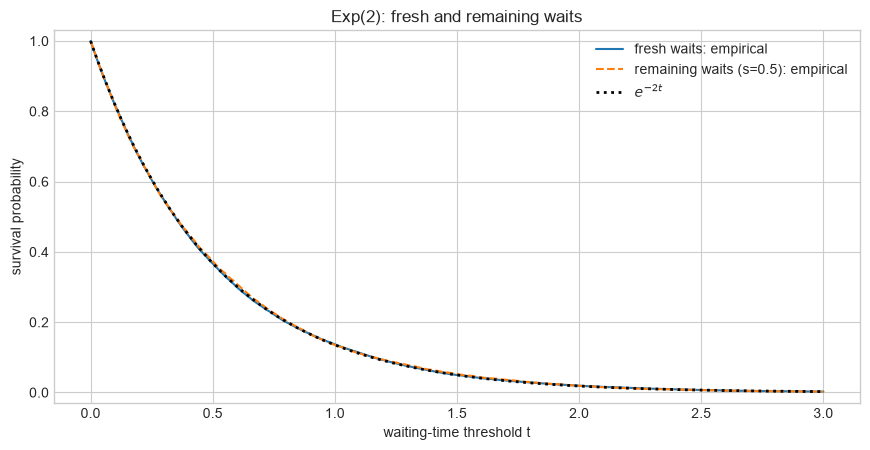


  u    Exp(2) quantile    fresh empirical    remaining empirical
 0.1         0.052680           0.052095              0.051541
 0.5         0.346574           0.345802              0.346421
 0.9         1.151293           1.158235              1.161801

max |empirical - e^(-2t)| on t ∈ [0, 3] (601 points):
  fresh waits:     0.00320
  remaining waits: 0.00754


In [28]:
def empirical_survival(sample, thresholds):
    sorted_sample = np.sort(sample)
    if sorted_sample.size == 0:
        raise ValueError("The empirical survival curve needs a nonempty sample.")
    return 1.0 - np.searchsorted(sorted_sample, thresholds, side="right") / sorted_sample.size


n_samples = 30_000
lambda_ = 2.0
s = 0.5
exponential = stats.expon(scale=1 / lambda_)            # scale = 1/λ = 0.5

waiting_sample = exponential.rvs(size=n_samples, random_state=rng)
residual_sample = waiting_sample[waiting_sample > s] - s
print(f"retained waits: {residual_sample.size} of {n_samples} "
      f"(theory: P(T > s) = {exponential.sf(s):.4f})")


t_grid = np.linspace(0, 3, 601)
fresh_surv = empirical_survival(waiting_sample, t_grid)
residual_surv = empirical_survival(residual_sample, t_grid)
theory_surv = exponential.sf(t_grid)

fig, ax = plt.subplots(figsize=(8.8, 4.6))
ax.plot(t_grid, fresh_surv, color="tab:blue", label="fresh waits: empirical")
ax.plot(t_grid, residual_surv, color="tab:orange", linestyle="--", label=f"remaining waits (s={s:g}): empirical")
ax.plot(t_grid, theory_surv, color="black", linestyle=":", linewidth=2.0, label=r"$e^{-2t}$")
ax.set_xlabel("waiting-time threshold t")
ax.set_ylabel("survival probability")
ax.set_title("Exp(2): fresh and remaining waits")
ax.set_ylim(-0.03, 1.03)
ax.legend()
plt.tight_layout()
plt.show()

# Quantile table
u_values = np.array([0.1, 0.5, 0.9])
theory_q = exponential.ppf(u_values)                     # -ln(1-u)/λ
fresh_q = np.quantile(waiting_sample, u_values, method="inverted_cdf")
residual_q = np.quantile(residual_sample, u_values, method="inverted_cdf")

print("\n  u    Exp(2) quantile    fresh empirical    remaining empirical")
for u, q_th, q_f, q_r in zip(u_values, theory_q, fresh_q, residual_q):
    print(f"{u:4.1f}   {q_th:14.6f}   {q_f:16.6f}   {q_r:19.6f}")

# Largest absolute discrepancy from e^{-2t} on the grid
print(f"\nmax |empirical - e^(-2t)| on t ∈ [0, 3] (601 points):")
print(f"  fresh waits:     {np.max(np.abs(fresh_surv - theory_surv)):.5f}")
print(f"  remaining waits: {np.max(np.abs(residual_surv - theory_surv)):.5f}")

retained waits: 14927 of 30000 (theory: P(T > s) = 0.5000)


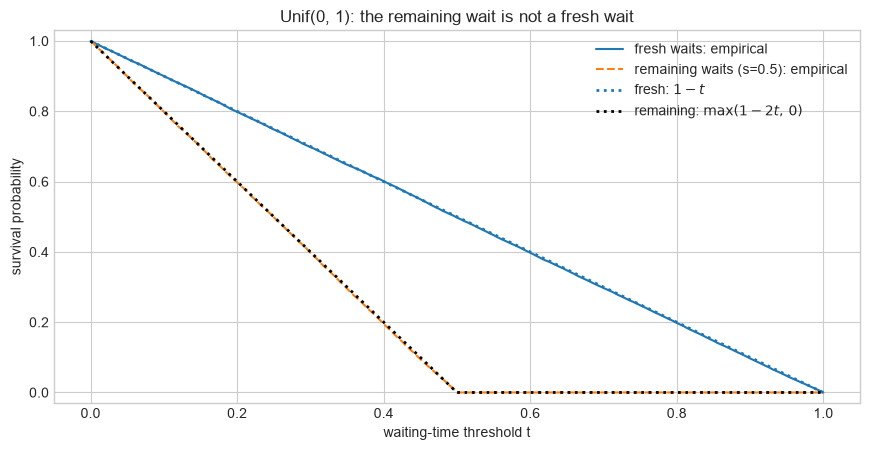


max discrepancy on t ∈ [0, 1] (201 points):
  fresh vs 1 - t:              0.00370
  remaining vs max(1-2t, 0):   0.00635
  remaining vs fresh law 1-t:  0.50000


In [29]:
uniform_waiting = stats.uniform(loc=0.0, scale=1.0)
uniform_waits = uniform_waiting.rvs(size=n_samples, random_state=rng)
uniform_residual = uniform_waits[uniform_waits > s] - s
print(f"retained waits: {uniform_residual.size} of {n_samples} "
      f"(theory: P(T > s) = {uniform_waiting.sf(s):.4f})")

u_grid = np.linspace(0, 1, 201)                          # t = 0, 0.005, ..., 1
fresh_surv_u = empirical_survival(uniform_waits, u_grid)
residual_surv_u = empirical_survival(uniform_residual, u_grid)
fresh_theory_u = uniform_waiting.sf(u_grid)                               # 1 - t on [0, 1]
residual_theory_u = uniform_waiting.sf(s + u_grid) / uniform_waiting.sf(s)  # max(1 - 2t, 0)

fig, ax = plt.subplots(figsize=(8.8, 4.6))
ax.plot(u_grid, fresh_surv_u, color="tab:blue", label="fresh waits: empirical")
ax.plot(u_grid, residual_surv_u, color="tab:orange", linestyle="--", label=f"remaining waits (s={s:g}): empirical")
ax.plot(u_grid, fresh_theory_u, color="tab:blue", linestyle=":", linewidth=2.0, label=r"fresh: $1-t$")
ax.plot(u_grid, residual_theory_u, color="black", linestyle=":", linewidth=2.0, label=r"remaining: $\max(1-2t,\,0)$")
ax.set_xlabel("waiting-time threshold t")
ax.set_ylabel("survival probability")
ax.set_title("Unif(0, 1): the remaining wait is not a fresh wait")
ax.set_ylim(-0.03, 1.03)
ax.legend()
plt.tight_layout()
plt.show()

print(f"\nmax discrepancy on t ∈ [0, 1] (201 points):")
print(f"  fresh vs 1 - t:              {np.max(np.abs(fresh_surv_u - fresh_theory_u)):.5f}")
print(f"  remaining vs max(1-2t, 0):   {np.max(np.abs(residual_surv_u - residual_theory_u)):.5f}")
print(f"  remaining vs fresh law 1-t:  {np.max(np.abs(residual_surv_u - fresh_theory_u)):.5f}")

P(T > s+t | T > s) = P(T > s+t) / P(T > s) = (1 − s − t)⁺ / (1 − s).